<a href="https://colab.research.google.com/github/kky-zs/100-days-ml/blob/main/notebooks/phase-1-ml-core/day-003-tabular-pipelines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tabular Pipelines

**Dataset**: the Adult Census Income (about 48k people, 14 features, predict whether income is above $50K). It has numeric and categorical columns, missing values, and class imbalance, like real company data.

## Part 1

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
                             classification_report, RocCurveDisplay,
                             PrecisionRecallDisplay, ConfusionMatrixDisplay)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 30)

## Part 2: Load the Data

In [2]:
adult = fetch_openml("adult", version=2, as_frame=True) # Downloads the dataset as a DataFrame
X, y = adult.data, adult.target
print(y.value_counts())

y = (y == ">50K").astype(int)
print("positive rate:", y.mean().round(3)) # should be around 0.24
print(X.shape)
X.head()

class
<=50K    37155
>50K     11687
Name: count, dtype: int64
positive rate: 0.239
(48842, 14)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States


In [3]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             48842 non-null  int64   
 1   workclass       46043 non-null  category
 2   fnlwgt          48842 non-null  int64   
 3   education       48842 non-null  category
 4   education-num   48842 non-null  int64   
 5   marital-status  48842 non-null  category
 6   occupation      46033 non-null  category
 7   relationship    48842 non-null  category
 8   race            48842 non-null  category
 9   sex             48842 non-null  category
 10  capital-gain    48842 non-null  int64   
 11  capital-loss    48842 non-null  int64   
 12  hours-per-week  48842 non-null  int64   
 13  native-country  47985 non-null  category
dtypes: category(8), int64(6)
memory usage: 2.6 MB


## Part 3: Split first

Anything learned from test data, even indirectly (imputation values, scaling statistics, feature choices, hyperparameters), makes the final score optimistic.

**stratify=y** keeps the class ratio equal in both parts.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(X_train.shape, X_test.shape)
print("train positive rate:", y_train.mean().round(3), "| test positive rate:", y_test.mean().round(3))

(39073, 14) (9769, 14)
train positive rate: 0.239 | test positive rate: 0.239


## Part 4: Look at the training data

Find out what needs handling: missing values, skewed columns, high-cardinality categoricals.

Missing values exist in a few categorical columns (like workclass and occupation), and missingness itself may carry information.

*capital-gain* and *capital-loss* are mostly zero with a huge right tail. (feature engineering (a log transform and a “has any” flag))

In [5]:
missing = X_train.isna().mean()
print("missing share per column:\n", missing[missing > 0].round(3))

print("\nnumeric summary:")
print(X_train.select_dtypes("number").describe().T[["mean", "50%", "max"]])

print("\ncategorical cardinality:")
print(X_train.select_dtypes(exclude="number").nunique())

print("\nshare of zeros in capital-gain / capital-loss:",
      (X_train["capital-gain"] == 0).mean().round(3), (X_train["capital-loss"] == 0).mean().round(3))

missing share per column:
 workclass         0.057
occupation        0.057
native-country    0.017
dtype: float64

numeric summary:
                         mean       50%        max
age                 38.697182      37.0       90.0
fnlwgt          189536.387250  178134.0  1484705.0
education-num       10.079262      10.0       16.0
capital-gain      1057.468610       0.0    99999.0
capital-loss        89.952269       0.0     4356.0
hours-per-week      40.457016      40.0       99.0

categorical cardinality:
workclass          8
education         16
marital-status     7
occupation        14
relationship       6
race               5
sex                2
native-country    41
dtype: int64

share of zeros in capital-gain / capital-loss: 0.918 0.952


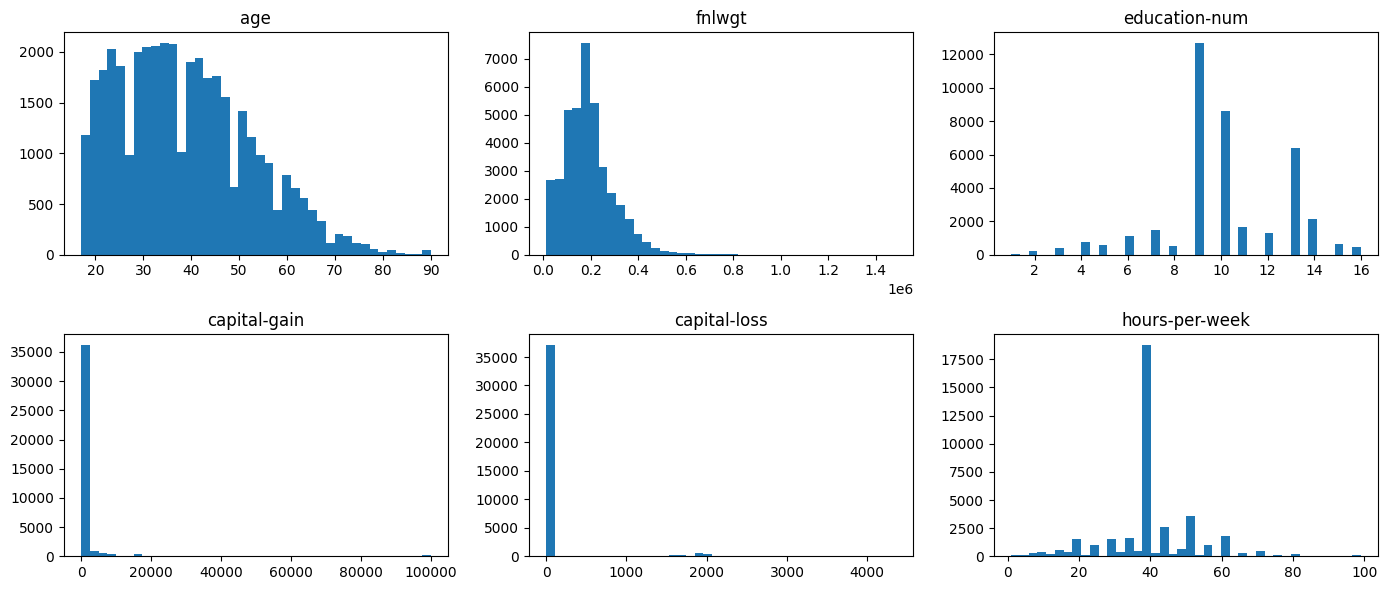

In [6]:
num_cols = X_train.select_dtypes("number").columns
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, col in zip(axes.ravel(), num_cols):
    ax.hist(X_train[col], bins=40)
    ax.set_title(col)
plt.tight_layout(); plt.show()

## Part 5: What is leakage?

**Preprocessing leakage**: fitting imputers, scalers, encoders, feature selectors, etc. on data that includes validation or test rows.

**Target leakage**: a feature that is derived from the outcome or recorded after it (for example “was_refunded” when predicting churn).


**Duplicate or group leakage**: the same entity (customer, patient, device) appears in both train and validation.

**Temporal leakage**: using future information to predict the past.

Demo of kind 1. The data is pure noise: random features, random labels. No model can do better than 50%. The wrong way, selecting the “best” 20 features using all the data and then cross-validating, still looks great. The right way puts the selector inside a pipeline so it is refit on each training fold. The wrong way to land around 0.8-0.9 and the right way near 0.5. Same data, same model. The only difference is when the selector saw the labels.

In [7]:
rng = np.random.default_rng(0)
X_noise = rng.normal(size=(100, 5000))
y_noise = rng.integers(0, 2, 100)
cv_demo = StratifiedKFold(5, shuffle=True, random_state=0)

# WRONG: feature selection sees all labels before cross-validation
X_selected = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)
wrong = cross_val_score(LogisticRegression(max_iter=1000), X_selected, y_noise, cv=cv_demo).mean()

# RIGHT: selection happens inside each fold
pipe_demo = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))
right = cross_val_score(pipe_demo, X_noise, y_noise, cv=cv_demo).mean()

print(f"wrong way (leaky): accuracy = {wrong:.3f}")
print(f"right way (pipeline): accuracy = {right:.3f}   (chance = 0.5)")

wrong way (leaky): accuracy = 0.870
right way (pipeline): accuracy = 0.500   (chance = 0.5)


## Part 6: Metrics and baselines

About 76% of people earn ≤ $50K, so a model that always says “≤ $50K” is 76% accurate and completely useless. We need metrics that see through that:

**ROC AUC**: the probability that a random positive gets a higher score than a random negative. 0.5 means random ranking.

**PR AUC (average precision)**: focuses on the positive class. Its random baseline equals the positive rate (~0.24), so numbers look lower but are more informative on imbalanced data.

**Accuracy**: reported only to show how misleading it is.

We evaluate with stratified 5-fold cross-validation on the training set, and report the mean ± std across folds plus the train score, so we can see overfitting (a big train-vs-CV gap).

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "accuracy": "accuracy"}

def cv_report(estimator, X, y, name):
    res = cross_validate(estimator, X, y, cv=cv, scoring=scoring, return_train_score=True)
    row = {"model": name}
    for k in scoring:
        row[f"{k} (cv)"] = f"{res['test_' + k].mean():.3f} ± {res['test_' + k].std():.3f}"
        row[f"{k} (train)"] = f"{res['train_' + k].mean():.3f}"
    return row

In [9]:
# Baseline: the dumb model that always predicts the majority class. Every real model must beat this.
# Expect: accuracy ≈ 0.76, ROC AUC = 0.5, PR AUC ≈ 0.24. High accuracy, zero skill.

X_dummy = np.zeros((len(X_train), 1))     # the dummy model ignores features anyway
baseline_rows = [cv_report(DummyClassifier(strategy="most_frequent"), X_dummy, y_train, "dummy: always majority")]
pd.DataFrame(baseline_rows).set_index("model")

,roc_auc (cv),roc_auc (train),pr_auc (cv),pr_auc (train),accuracy (cv),accuracy (train)
model,,,,,,
dummy: always majority,0.500 ± 0.000,0.500,0.239 ± 0.000,0.239,0.761 ± 0.000,0.761


## Part 7: The leak-proof pipeline

**Feature engineering**: log1p of capital gain/loss and a “has capital gain” flag. These are row-wise transformations with no learned statistics, so they can’t leak.

**ColumnTransformer**: numeric columns get a median imputer and a standard scaler. Categorical columns get a “missing” imputer and a one-hot encoder with handle_unknown="ignore" (so a category never seen in training doesn’t crash prediction).

**The model.**

**The key point**: imputers, scalers and encoders learn statistics (medians, means, category lists). Inside a pipeline, those statistics are learned only from whatever data you call fit on. When cross-validation fits the pipeline on a training fold, the validation fold is only transformed with the training fold’s statistics.

In [10]:
def add_capital_features(df):
    df = df.copy()
    df["capital-gain-log"] = np.log1p(df["capital-gain"])
    df["capital-loss-log"] = np.log1p(df["capital-loss"])
    df["has-capital-gain"] = (df["capital-gain"] > 0).astype(int)
    return df


def make_preprocessor(scale=True):
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), make_column_selector(dtype_include=np.number)),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="missing")),
            # encoder returns a dense array (sparse_output=False) so that models like histogram gradient boosting can consume it too.
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            # dtype_exclude=np.number: to catch category, object and string dtypes alike.
        ]), make_column_selector(dtype_exclude=np.number)), # picks columns by dtype at fit time, the engineered numeric columns are included automatically
    ])


def build(model, scale=True):
    return Pipeline([
        ("features", FunctionTransformer(add_capital_features)),
        ("prep", make_preprocessor(scale)),
        ("model", model),
    ])

pipe_lr = build(LogisticRegression(max_iter=1000))
pipe_lr

Pipeline(steps=[('features',
                 FunctionTransformer(func=<function add_capital_features at 0x7ed2311e6d40>)),
                ('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7ed23398e270>),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(fill_value='missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7ed2312eb9d0>)])),
                ('model', LogisticRegression(max_iter=1000))])

In [11]:
# Peek at what the preprocessing produces.
prep_preview = Pipeline(pipe_lr.steps[:-1]).fit(X_train)
names = prep_preview.named_steps["prep"].get_feature_names_out()
print(len(names), "features after preprocessing")
print(list(names[:8]), "...")

111 features after preprocessing
['num__age', 'num__fnlwgt', 'num__education-num', 'num__capital-gain', 'num__capital-loss', 'num__hours-per-week', 'num__capital-gain-log', 'num__capital-loss-log'] ...


## Part 8: Compare models properly

**Logistic regression**: a strong, simple, interpretable baseline.

**HistGradientBoostingClassifier**: a modern tree ensemble.

Read the table for: (1) beating the dummy, (2) the gap between train and CV scores, and (3) the std across folds.

Rough expectation on the real dataset: logistic regression around 0.90-0.91 ROC AUC and gradient boosting a bit higher, around 0.92-0.94, with accuracies of about 0.85 and 0.87. Pick the winner by the CV numbers. The test set stays locked.

In [12]:
rows = list(baseline_rows)
rows.append(cv_report(build(LogisticRegression(max_iter=1000)), X_train, y_train, "logistic regression"))
rows.append(cv_report(build(HistGradientBoostingClassifier(random_state=RANDOM_STATE), scale=False),
                      X_train, y_train, "hist gradient boosting"))
results = pd.DataFrame(rows).set_index("model")
results

,roc_auc (cv),roc_auc (train),pr_auc (cv),pr_auc (train),accuracy (cv),accuracy (train)
model,,,,,,
dummy: always majority,0.500 ± 0.000,0.500,0.239 ± 0.000,0.239,0.761 ± 0.000,0.761
logistic regression,0.909 ± 0.004,0.911,0.775 ± 0.011,0.778,0.854 ± 0.005,0.856
hist gradient boosting,0.928 ± 0.003,0.944,0.827 ± 0.007,0.860,0.872 ± 0.005,0.885


## Part 9: Hunting for leakage

We plant a leaky feature into a copy of the training data, then detect it.

**Plant a leak**: post_outcome_flag copies the target with 5% of values flipped, like a field that gets filled in after the outcome is known (think “account_flagged_by_audit”). It is visible in the training data and absent at real prediction time.

In [13]:
rng2 = np.random.default_rng(1)
X_leaky = X_train.copy()
X_leaky["post_outcome_flag"] = np.where(rng2.random(len(X_leaky)) < 0.05, 1 - y_train, y_train)

leak_row = cv_report(build(LogisticRegression(max_iter=1000)), X_leaky, y_train, "logistic regression + leaky feature")
pd.DataFrame([rows[2], leak_row]).set_index("model")

,roc_auc (cv),roc_auc (train),pr_auc (cv),pr_auc (train),accuracy (cv),accuracy (train)
model,,,,,,
hist gradient boosting,0.928 ± 0.003,0.944,0.827 ± 0.007,0.860,0.872 ± 0.005,0.885
logistic regression + leaky feature,0.989 ± 0.000,0.989,0.968 ± 0.002,0.969,0.966 ± 0.001,0.967


**Red flag #1**: the scores jump to about 0.98 ROC AUC, far above anything the honest features reach.

**Detection tool**: single-feature scan. For each column alone, train a tiny decision tree and measure its cross-validated AUC. A feature that is far above all the others deserves suspicion.

post_outcome_flag    0.948
relationship         0.781
marital-status       0.773
occupation           0.728
education-num        0.716
education            0.713
age                  0.706
hours-per-week       0.675
sex                  0.619
capital-gain         0.609
workclass            0.584
capital-loss         0.556
race                 0.539
native-country       0.522
fnlwgt               0.517
dtype: float64


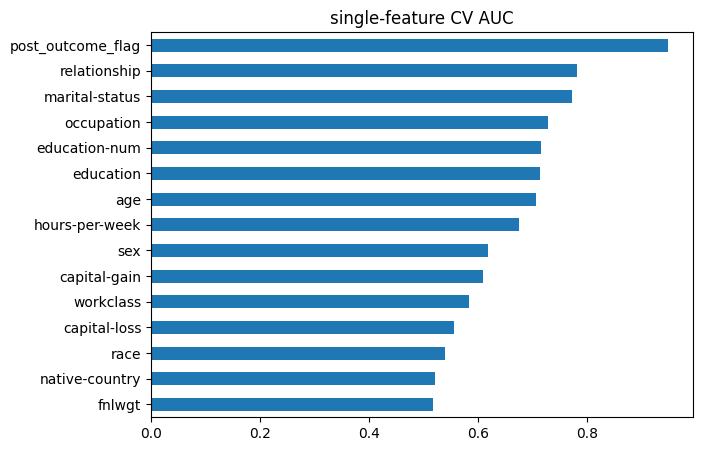

In [14]:
def single_feature_cv_auc(X, y, cols=None):
    out = {}
    for col in (cols or list(X.columns)):
        s = X[[col]]
        if pd.api.types.is_numeric_dtype(s[col]):
            prep = SimpleImputer(strategy="median")
        else:
            prep = Pipeline([
                ("impute", SimpleImputer(strategy="constant", fill_value="missing")),
                ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
            ])
        pipe = make_pipeline(prep, DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE))
        out[col] = cross_val_score(pipe, s, y, cv=3, scoring="roc_auc").mean()
    return pd.Series(out).sort_values(ascending=False)

scan = single_feature_cv_auc(X_leaky, y_train)
print(scan.round(3))
scan.plot.barh(figsize=(7, 5)); plt.gca().invert_yaxis(); plt.title("single-feature CV AUC"); plt.show()

**Red flag #2**: post_outcome_flag alone scores about 0.95, while genuine features like relationship or education-num sit well below it.

**Duplicate check**. Exact duplicates across the train/test split inflate scores for models that memorize.

A few duplicates in a dataset this size are normal and not a big problem. Large overlaps would be. If your data has several rows per person, customer or device, use GroupKFold so each group stays on one side of the split, and for time-ordered data use time-based splits (TimeSeriesSplit). The pipeline protects you from preprocessing leakage, but it can’t fix a bad split strategy.

In [15]:
print("duplicate rows inside X_train:", X_train.duplicated().sum())

dup_overlap = X_train.assign(_y=y_train).merge(
    X_test.drop_duplicates(), how="inner", on=list(X_train.columns)
)
print("train rows that also appear in the test set:", len(dup_overlap))

duplicate rows inside X_train: 35
train rows that also appear in the test set: 21


## Part 10: The final test, once

We refit the chosen pipeline on the full training set (not on CV folds) and evaluate on the test set once. Use gradient boosting below.

In [16]:
final_model = build(HistGradientBoostingClassifier(random_state=RANDOM_STATE), scale=False)
final_model.fit(X_train, y_train)

proba = final_model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(f"TEST ROC AUC : {roc_auc_score(y_test, proba):.4f}")
print(f"TEST PR AUC  : {average_precision_score(y_test, proba):.4f}   (random baseline = {y_test.mean():.3f})")
print(f"TEST accuracy: {accuracy_score(y_test, pred):.4f}")
print()
print(classification_report(y_test, pred, target_names=["<=50K", ">50K"]))

TEST ROC AUC : 0.9290
TEST PR AUC  : 0.8316   (random baseline = 0.239)
TEST accuracy: 0.8757

              precision    recall  f1-score   support

       <=50K       0.90      0.95      0.92      7431
        >50K       0.79      0.65      0.72      2338

    accuracy                           0.88      9769
   macro avg       0.84      0.80      0.82      9769
weighted avg       0.87      0.88      0.87      9769



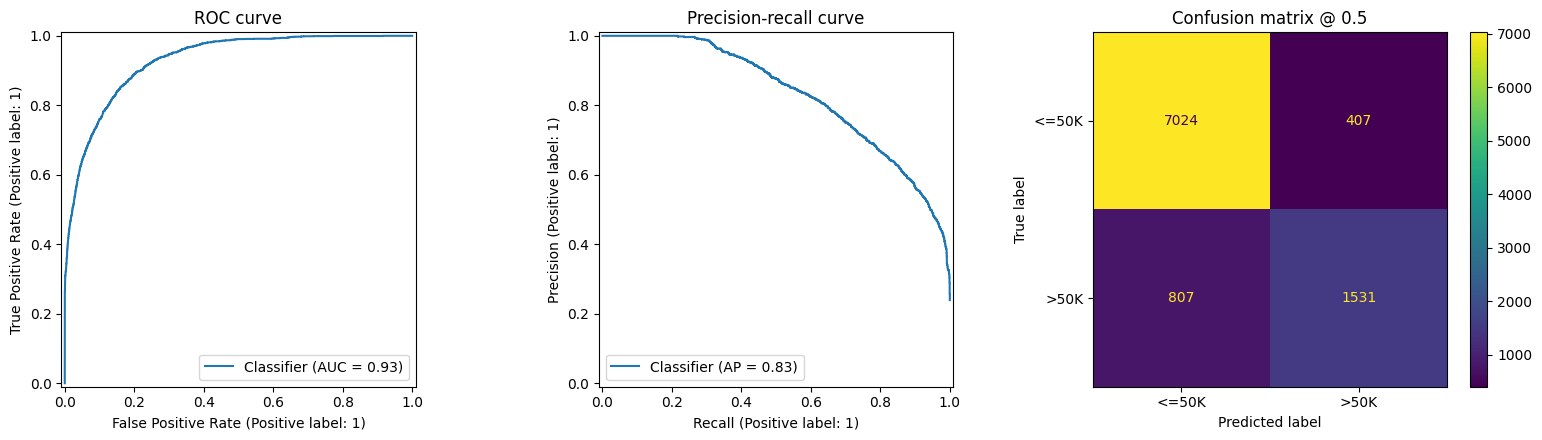

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
RocCurveDisplay.from_predictions(y_test, proba, ax=ax[0]); ax[0].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_test, proba, ax=ax[1]); ax[1].set_title("Precision-recall curve")
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["<=50K", ">50K"], ax=ax[2])
ax[2].set_title("Confusion matrix @ 0.5")
plt.tight_layout(); plt.show()

## Part 11: Save and reload the whole pipeline

The pipeline object holds the engineered features, imputers, encoders and the model, so you ship one file and call predict_proba on raw rows.

In [18]:
Path("models").mkdir(exist_ok=True)
joblib.dump(final_model, "models/adult_income_pipeline.joblib")

loaded = joblib.load("models/adult_income_pipeline.joblib")
sample = X_test.head(3)
print(loaded.predict_proba(sample)[:, 1])
print(final_model.predict_proba(sample)[:, 1])      # identical

[0.17659613 0.00515945 0.67575575]
[0.17659613 0.00515945 0.67575575]
